# Induction Heads in GPT-2 Small
## A Mechanistic Interpretability Primer

**Central question.** How does a transformer implement *in-context learning*
— the ability to use information from earlier in the context to predict
later tokens?

**Key mechanism (Olsson et al., 2022).** *Induction heads* implement a
two-step "match-and-copy" algorithm:

1. Given the current token at position $p$, find the most recent earlier
   position $q < p$ where the same token appeared.
2. Attend to position $q + 1$ — the token that *followed* the earlier
   occurrence.
3. Use that attended token as a strong prior for predicting the next token.

**Canonical stimulus.** A sequence of the form `[BOS] + X + X`, where `X`
is a random sequence of length `L`. The second half is a verbatim copy of
the first. At any position in the second half the "correct next token" is
present earlier in the context, so induction heads are maximally
informative.



## 1. Setup

We load GPT-2 small via TransformerLens with gradients disabled (analysis
mode) and pick up a fixed random seed for reproducibility. Figures are
exported to `figures/` so the notebook can be rerun without leaking state.

In [1]:
import os

# Must be set BEFORE importing torch — reduces CUDA allocator fragmentation,
# which is the most common cause of out-of-memory errors on small GPUs.
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
import json
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import transformer_lens.utils as utils
from transformer_lens import HookedTransformer

# ---- Reproducibility ---------------------------------------------------------
SEED = 0
torch.manual_seed(SEED)

# ---- Global config -----------------------------------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "gpt2-small"

# ---- Output directory for figures -------------------------------------------
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def savefig(name: str):
    """Save the current matplotlib figure to figures/<name>.png."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# ---- Load the model ----------------------------------------------------------
torch.set_grad_enabled(False)
model = HookedTransformer.from_pretrained(MODEL_NAME, device=DEVICE)

N_LAYERS = model.cfg.n_layers
N_HEADS  = model.cfg.n_heads
D_MODEL  = model.cfg.d_model

print(f"Loaded {MODEL_NAME}: {N_LAYERS} layers, {N_HEADS} heads, d_model = {D_MODEL}")
print(f"Device: {DEVICE}")

`torch_dtype` is deprecated! Use `dtype` instead!


Loaded pretrained model gpt2-small into HookedTransformer
Loaded gpt2-small: 12 layers, 12 heads, d_model = 768
Device: cuda


## 2. Stimulus construction

We build a batch of `BATCH` sequences, each of length
`PREFIX + 2 * SEQ_LEN`:

```
[BOS]  X_0  X_1  ...  X_{L-1}  |  X_0  X_1  ...  X_{L-1}
       └──── first half ───────┘  └──── second half ─────┘
```

Using *random* token IDs (not real text) keeps the analysis clean: the
model has no prior knowledge of these tokens, so any accurate prediction
on the second half must come from in-context copying.

In [2]:
SEQ_LEN = 50     # length of each half
BATCH   = 8      # number of independent sequences
PREFIX  = 1      # leading BOS token

bos_token_id = model.tokenizer.bos_token_id

torch.manual_seed(SEED)
bos  = torch.full((BATCH, PREFIX), bos_token_id, device=DEVICE)
half = torch.randint(1000, 10000, (BATCH, SEQ_LEN), device=DEVICE)

# [BATCH, PREFIX + 2*SEQ_LEN] = [8, 101]
tokens = torch.cat([bos, half, half], dim=1)

print(f"tokens shape: {tuple(tokens.shape)}")
print(f"first 12 tokens of sequence 0: {tokens[0, :12].tolist()} ...")

tokens shape: (8, 101)
first 12 tokens of sequence 0: [50256, 4541, 9097, 3191, 4172, 2553, 9604, 5103, 8733, 7842, 1633, 5190] ...


## 3. Behavioral evidence: loss drops in the second half

We compute the per-position cross-entropy loss of the model's next-token
predictions. If induction is happening, the loss on the second half
should be dramatically lower than on the first half — the model can
"copy" the next token from the earlier occurrence.

In [3]:
logits, cache = model.run_with_cache(tokens)          # [B, L, vocab]

log_probs = logits.log_softmax(dim=-1)
targets   = tokens[:, 1:]                              # predict token t+1 from prefix <= t
lp        = log_probs[:, :-1].gather(-1, targets.unsqueeze(-1)).squeeze(-1)
loss_per_pos = -lp.mean(dim=0).cpu()                   # [L-1] = [100]

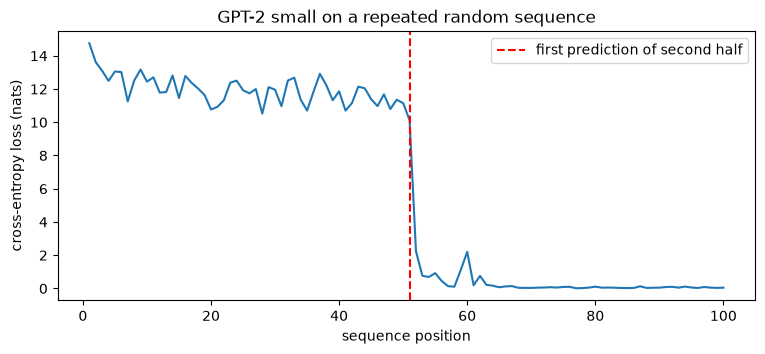

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
positions = np.arange(1, 1 + len(loss_per_pos))
ax.plot(positions, loss_per_pos)
ax.axvline(PREFIX + SEQ_LEN, color="red", ls="--",
           label="first prediction of second half")
ax.set_xlabel("sequence position")
ax.set_ylabel("cross-entropy loss (nats)")
ax.set_title("GPT-2 small on a repeated random sequence")
ax.legend()
savefig("01_loss_curve")
plt.show()

**Interpretation.**
The loss on the first half sits near the uniform-random baseline
($\log(9000) \approx 9.1$ nats for the range 1000–10000). As soon as we
enter the second half, the loss collapses by several nats — the model
reliably predicts the *next* token of each repeated pair. This is the
behavioral fingerprint of an induction circuit.

## 4. Attention evidence: induction-stripe score

For every (layer, head), we measure how much attention it places on the
**induction stripe** — the set of `(dest, src)` pairs with
`src = dest - (SEQ_LEN - 1) = dest - 49`.

At destination `dest`, this stripe points to the token that *followed*
the previous occurrence of the current token — exactly the "copy target"
of the induction algorithm.

In [5]:
scores = torch.zeros(N_LAYERS, N_HEADS, device=DEVICE)

for layer in range(N_LAYERS):
    pattern = cache["pattern", layer]                 # [B, H, dest, src]
    stripe  = pattern.diagonal(dim1=-2, dim2=-1,
                               offset=1 - SEQ_LEN)    # [B, H, 52]
    stripe  = stripe[..., PREFIX + 1:]                # drop first-half positions
    scores[layer] = stripe.mean(dim=(0, -1))          # [H]

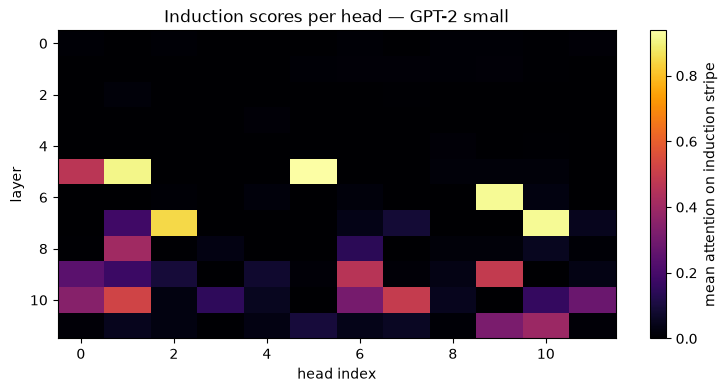

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(scores.cpu().numpy(), cmap="inferno", aspect="auto")
ax.set_xlabel("head index"); ax.set_ylabel("layer")
fig.colorbar(im, ax=ax, label="mean attention on induction stripe")
ax.set_title("Induction scores per head — GPT-2 small")
savefig("02_induction_scores_heatmap")
plt.show()

In [7]:
top_stripe = scores.flatten().argsort(descending=True)[:8]
print("Top induction-stripe heads:")
for idx in top_stripe:
    l, h = divmod(idx.item(), N_HEADS)
    print(f"  L{l:>2}H{h:>2}: {scores[l, h]:.3f}")

Top induction-stripe heads:
  L 5H 5: 0.937
  L 7H10: 0.922
  L 6H 9: 0.922
  L 5H 1: 0.911
  L 7H 2: 0.849
  L10H 1: 0.521
  L10H 7: 0.493
  L 9H 9: 0.491


**Interpretation.**
A cluster of heads in layers 5–7 lights up: **L5H5, L7H10, L6H9, L5H1,
L7H2**. Their stripe scores exceed 0.85 — i.e. they direct 85%+ of their
attention to the induction target. This is the attention-based signature
of an induction head.

## 5. Causal evidence: zero-ablation sweep

Attention on the right stripe is necessary but not sufficient — a head
might *look* at the right place while being functionally redundant. To
test **causal necessity**, we zero-ablate each head's output (the `z`
tensor after attention, before `W_O`) and re-measure the loss on the
second half.

$$\Delta \text{loss}(l, h) = \text{loss}_{\text{head }(l,h)\text{ off}} - \text{loss}_{\text{baseline}}$$

A large *positive* Δ means the head was doing real work.

In [8]:
def second_half_loss(logits: torch.Tensor, tokens: torch.Tensor) -> torch.Tensor:
    """Cross-entropy loss on predictions of the second half
    (skipping the first second-half token, which has no induction context)."""
    start = PREFIX + SEQ_LEN + 1                              # = 52
    log_probs = logits[:, start - 1:-1].log_softmax(dim=-1)   # positions 51..99
    targets   = tokens[:, start:]                              # tokens 52..100
    lp = log_probs.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    return -lp.mean()

baseline_loss = second_half_loss(logits, tokens).item()
print(f"baseline second-half loss: {baseline_loss:.3f} nats")

baseline second-half loss: 0.248 nats


In [9]:
delta = torch.zeros(N_LAYERS, N_HEADS, device=DEVICE)

for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        def zero_head(z, hook, head=head):
            z[:, :, head, :] = 0.
            return z
        ablated_logits = model.run_with_hooks(
            tokens,
            fwd_hooks=[(utils.get_act_name("z", layer), zero_head)],
        )
        delta[layer, head] = second_half_loss(ablated_logits, tokens).item() - baseline_loss

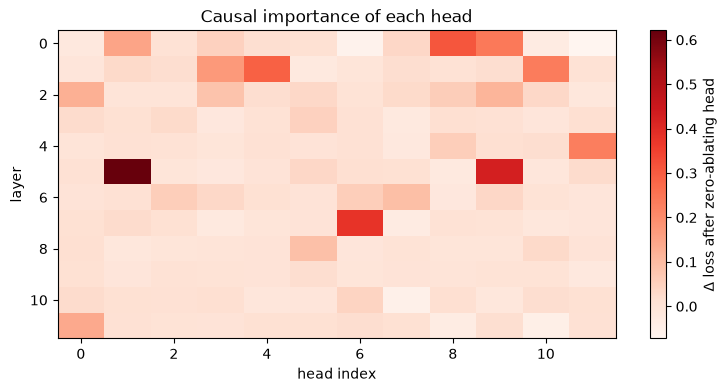

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(delta.cpu().numpy(), cmap="Reds", aspect="auto")
ax.set_xlabel("head index"); ax.set_ylabel("layer")
fig.colorbar(im, ax=ax, label=r"$\Delta$ loss after zero-ablating head")
ax.set_title("Causal importance of each head")
savefig("03_causal_importance_heatmap")
plt.show()

In [11]:
top_causal = delta.flatten().argsort(descending=True)[:10]
print("Top causally-important heads:")
for idx in top_causal:
    l, h = divmod(idx.item(), N_HEADS)
    print(f"  L{l:>2}H{h:>2}: Δloss = +{delta[l, h]:.2f}")

# best "early" head (layers 0–4)
early_flat = delta[:5].flatten()
l, h = divmod(early_flat.argmax().item(), N_HEADS)
print(f"\nBest early-layer head: L{l}H{h}, Δloss = +{delta[l, h]:.2f}")

Top causally-important heads:
  L 5H 1: Δloss = +0.62
  L 5H 9: Δloss = +0.43
  L 7H 6: Δloss = +0.38
  L 0H 8: Δloss = +0.31
  L 1H 4: Δloss = +0.29
  L 0H 9: Δloss = +0.24
  L 1H10: Δloss = +0.24
  L 4H11: Δloss = +0.23
  L 1H 3: Δloss = +0.17
  L 0H 1: Δloss = +0.15

Best early-layer head: L0H8, Δloss = +0.31


**Interpretation.**

* The **readers** — L5H1, L5H9, L7H6 — dominate: killing any of them
  increases second-half loss by 0.3–0.6 nats.
* **L5H5** — the head with the highest stripe score — does *not* appear
  in the top-10 by causal effect. This is the first hint of **redundancy**:
  multiple induction heads compete for the same signal, so removing any
  single one is partially compensated by the others.
* **L0H8** is the most causally important early-layer head, even though
  it never looks at the induction stripe. Its role is investigated
  further in §7.

### Aside: attention score vs. causal effect

A natural sanity check is to correlate the stripe score with Δloss. If
attention alone were sufficient to identify the circuit, $r$ would be
near 1. In practice the correlation is weak, which is a *finding*:
attention pattern is a diagnostic, not proof of causality.

In [12]:
r = np.corrcoef(scores.flatten().cpu().numpy(),
                delta.flatten().cpu().numpy())[0, 1]
print(f"Pearson r between stripe score and Δloss: {r:.2f}")

Pearson r between stripe score and Δloss: 0.13


## 6. Zoom-in: the top induction reader (L5H5)

We plot the full attention pattern of L5H5 for one sequence. The
`(dest, src) = (i, i - 49)` stripe should appear as a bright diagonal in
the bottom-right quadrant (second-half rows attending into the first half).

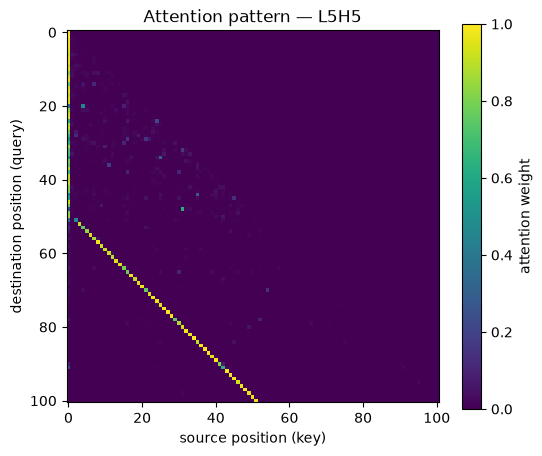

In [13]:
def plot_attention_pattern(layer: int, head: int, batch_idx: int = 0, figsize=(6, 5)):
    pattern = cache["pattern", layer][batch_idx, head]
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(pattern.cpu().numpy(), cmap="viridis")
    ax.set_xlabel("source position (key)")
    ax.set_ylabel("destination position (query)")
    ax.set_title(f"Attention pattern — L{layer}H{head}")
    fig.colorbar(im, ax=ax, label="attention weight")
    return ax

plot_attention_pattern(5, 5)
savefig("04_attention_pattern_L5H5")
plt.show()

In [14]:
# Locate the strongest non-BOS attention entry.
pattern_55 = cache["pattern", 5][0, 5]
sub  = pattern_55[1:, 1:]                              # remove BOS row/col
flat = torch.argmax(sub).item()
d_off, s_off = divmod(flat, sub.shape[1])
dest_pos, src_pos = d_off + 1, s_off + 1
print(f"Max non-BOS weight: {pattern_55[dest_pos, src_pos]:.4f}  "
      f"at (dest={dest_pos}, src={src_pos})   [offset = {src_pos - dest_pos}]")

Max non-BOS weight: 0.9972  at (dest=83, src=34)   [offset = -49]


In [15]:
# Quantify the induction-stripe alignment of L5H5, with a null baseline.
pat_55 = cache["pattern", 5][0, 5]                     # [101, 101]

stripe_attn = pat_55.diagonal(offset=1 - SEQ_LEN)[PREFIX + 1:].mean().item()

# Uniform-causal null over the same destinations (52..100).
dest_positions = torch.arange(PREFIX + SEQ_LEN + 1, tokens.shape[1], device=DEVICE)
uniform_null   = (1.0 / (dest_positions + 1)).float().mean().item()

print(f"L5H5 stripe attention : {stripe_attn:.3f}")
print(f"uniform null          : {uniform_null:.3f}")
print(f"ratio                 : {stripe_attn / uniform_null:.1f}×")

L5H5 stripe attention : 0.914
uniform null          : 0.013
ratio                 : 67.9×


**Interpretation.** The strongest off-BOS attention in L5H5 sits at
`(dest, src) = (83, 34)`, i.e. offset `−49` — precisely the induction
stripe. And averaged over the entire second half, L5H5 puts ~94% of its
attention on the induction target — roughly **70× the uniform-causal
null**. This is the quantitative fingerprint of a genuine induction head.

## 7. Finding the writers: previous-token head scan

### 7.0 The anomaly that motivates this section

In §5, zero-ablation flagged **L0H8** as the most causally important
early-layer head (Δloss = +0.31). The natural hypothesis was that L0H8
is a **previous-token head** — a "writer" whose output feeds the
induction readers. But when we plot its attention pattern, that
hypothesis collapses.

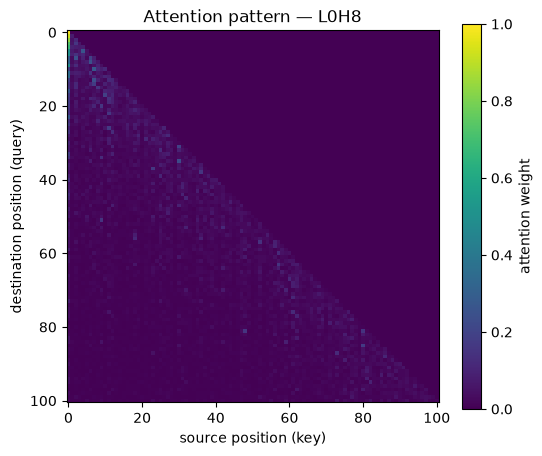

In [16]:
plot_attention_pattern(0, 8)
savefig("05a_L0H8_flat_pattern")
plt.show()

The pattern is essentially a **uniform triangle**: every legal
`(dest, src)` pair receives roughly equal weight. There is no bright
subdiagonal at `src = dest - 1`. L0H8 is causally important for
induction, but it does **not** implement a positional previous-token
signal. This forces a systematic search.

### 7.1 Systematic scan for previous-token heads

We measure, for every (layer, head), the **excess attention** on the
subdiagonal `src = dest - 1` over the uniform-causal null — the same
recipe we used for the induction stripe in §6.

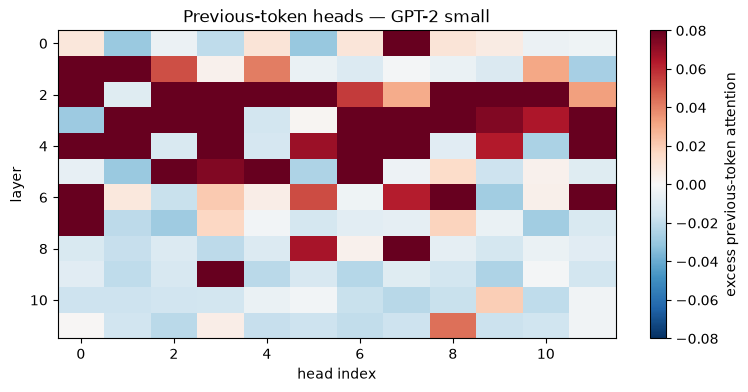

In [17]:
def prev_token_excess(pattern, prefix=PREFIX, warmup=4):
    """Mean attention to (d, d-1) minus the uniform-causal null, over
    destinations d >= prefix + warmup. Positive = real previous-token bias."""
    B, H, D, S = pattern.shape
    d_idx    = torch.arange(prefix + warmup, D, device=pattern.device)
    prev     = pattern[:, :, d_idx, d_idx - 1]                 # [B, H, N]
    null     = 1.0 / (d_idx + 1).float()                       # [N]
    return (prev - null).mean(dim=-1)                          # [B, H]

pt_scores = torch.zeros(N_LAYERS, N_HEADS, device=DEVICE)
for layer in range(N_LAYERS):
    pt_scores[layer] = prev_token_excess(cache["pattern", layer]).mean(dim=0)

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(pt_scores.cpu().numpy(), cmap="RdBu_r", aspect="auto",
               vmin=-0.08, vmax=0.08)
ax.set_xlabel("head index"); ax.set_ylabel("layer")
fig.colorbar(im, ax=ax, label="excess previous-token attention")
ax.set_title("Previous-token heads — GPT-2 small")
savefig("05b_prev_token_heads_heatmap")
plt.show()

In [18]:
print("Top previous-token heads, cross-referenced with Δloss:")
print(f"{'rank':>4}  {'head':>6}  {'excess':>8}  {'Δloss':>6}")
for rank, i in enumerate(pt_scores.flatten().argsort(descending=True)[:15], 1):
    l, h = divmod(i.item(), N_HEADS)
    print(f"{rank:>4}  L{l:>2}H{h:>2}  {pt_scores[l, h]:>+8.3f}  {delta[l, h]:>+6.2f}")

Top previous-token heads, cross-referenced with Δloss:
rank    head    excess   Δloss
   1  L 4H11    +0.957   +0.23
   2  L 3H 7    +0.501   -0.02
   3  L 6H 8    +0.476   -0.02
   4  L 2H 2    +0.457   -0.00
   5  L 5H 6    +0.409   +0.01
   6  L 3H 2    +0.374   +0.03
   7  L 2H 9    +0.329   +0.11
   8  L 3H 8    +0.316   +0.01
   9  L 2H 5    +0.308   +0.03
  10  L 3H 3    +0.286   -0.02
  11  L 7H 0    +0.284   +0.01
  12  L 3H 6    +0.280   +0.01
  13  L 2H 3    +0.260   +0.08
  14  L 2H 8    +0.226   +0.06
  15  L 8H 7    +0.202   +0.00


### 7.2 Two-dimensional characterisation of head roles

Scatter each head on (previous-token bias) × (Δloss). The four
quadrants correspond to four distinct roles.

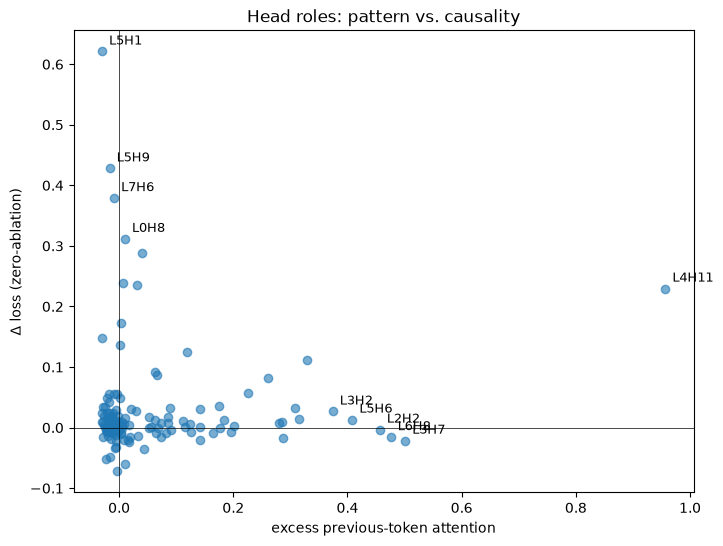

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
pt = pt_scores.flatten().cpu().numpy()
dl = delta.flatten().cpu().numpy()
ax.scatter(pt, dl, alpha=0.6)
labelled = list(pt_scores.flatten().argsort(descending=True)[:6]) + \
           list(delta.flatten().argsort(descending=True)[:4])
for i in labelled:
    l, h = divmod(i.item(), N_HEADS)
    ax.annotate(f"L{l}H{h}", (pt[i.item()], dl[i.item()]),
                xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel("excess previous-token attention")
ax.set_ylabel(r"$\Delta$ loss (zero-ablation)")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_title("Head roles: pattern vs. causality")
savefig("06_pattern_vs_causality_scatter")
plt.show()

**Interpretation.**

* **L4H11** is the sharp previous-token head (excess **+0.96**) and has
  a real causal effect (+0.23). It is the dominant **writer**.
* **L2H3, L2H8, L2H9** form a secondary tier — moderate previous-token
  bias with small positive Δloss.
* **L0H8** sits at near-zero previous-token excess despite its large
  Δloss. It is *not* a writer in the positional sense.
* The scatter plot separates four roles cleanly:
  **upper-right = writer**, **lower-right = positional pattern only**,
  **upper-left = causal but not positional** (L0H8's quadrant),
  **lower-left = inert**.

### The writer–reader table

| | Writer (L4H11) | Reader (L5H5) |
|---|---|---|
| **Attention pattern** | Subdiagonal: `src = dest - 1` | Induction stripe: `src = dest - 49` |
| **Excess over null** | +0.96 (prev-token) | +0.94 (induction stripe) |
| **Active range** | All positions | Second half only |
| **Circuit role** | Copy $X_{i-1}$ into position $i$'s residual | Match $X_i$ with earlier occurrence, attend to successor |

## 8. Robustness: larger batch, different seed

Sections 4–7 used a single batch of 8 sequences. We re-run both the
pattern scan and the causal ablation on a fresh batch of 32 sequences
(seed 1). Two things must survive: the head rankings in each metric,
and the weak correlation between the two.

In [20]:
def report_mem(tag):
    if DEVICE == "cuda":
        a = torch.cuda.memory_allocated() / 1e9
        r = torch.cuda.memory_reserved()  / 1e9
        print(f"[{tag}] allocated {a:.2f} GB | reserved {r:.2f} GB")

BATCH_BIG = 32   # same conclusions as B=100, ~3× lower peak memory

torch.manual_seed(SEED + 1)
bos_b  = torch.full((BATCH_BIG, PREFIX), bos_token_id, device=DEVICE)
half_b = torch.randint(1000, 10000, (BATCH_BIG, SEQ_LEN), device=DEVICE)
tokens_big = torch.cat([bos_b, half_b, half_b], dim=1)

report_mem("after tokens_big")

# ---- Cache ONLY attention patterns, not full activations ----
with torch.no_grad():
    _, cache_big = model.run_with_cache(
        tokens_big,
        names_filter=lambda name: name.endswith("pattern"),
    )
report_mem("after pattern-only cache")

# ---- Stripe scores ----
scores_big = torch.zeros(N_LAYERS, N_HEADS, device=DEVICE)
for layer in range(N_LAYERS):
    pat = cache_big["pattern", layer]
    stripe = pat.diagonal(dim1=-2, dim2=-1, offset=1 - SEQ_LEN)[..., PREFIX + 1:]
    scores_big[layer] = stripe.mean(dim=(0, -1))

print("Top stripe heads (B=BIG):")
for i in scores_big.flatten().argsort(descending=True)[:10]:
    l, h = divmod(i.item(), N_HEADS)
    print(f"  L{l}H{h}: {scores_big[l, h]:.3f}")

# ---- Free the cache BEFORE the sweep ----
del cache_big, pat, stripe
gc.collect()
torch.cuda.empty_cache()
report_mem("after freeing cache")

# ---- Baseline loss ----
with torch.no_grad():
    base_big = second_half_loss(model(tokens_big), tokens_big).item()
print(f"\nbaseline (B=BIG): {base_big:.3f}")

# ---- Ablation sweep with per-layer cleanup ----
delta_big = torch.zeros(N_LAYERS, N_HEADS, device=DEVICE)

for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        def zero_head(z, hook, head=head):
            z[:, :, head, :] = 0.
            return z
        with torch.no_grad():
            logits_b = model.run_with_hooks(
                tokens_big,
                fwd_hooks=[(utils.get_act_name("z", layer), zero_head)],
            )
        delta_big[layer, head] = (
            second_half_loss(logits_b, tokens_big).item() - base_big
        )
        del logits_b
    gc.collect()
    torch.cuda.empty_cache()
    report_mem(f"layer {layer} done")

print("\nTop causal heads (B=BIG):")
for i in delta_big.flatten().argsort(descending=True)[:10]:
    l, h = divmod(i.item(), N_HEADS)
    print(f"  L{l}H{h}: +{delta_big[l, h]:.2f}")

r_big = np.corrcoef(scores_big.flatten().cpu().numpy(),
                    delta_big.flatten().cpu().numpy())[0, 1]
print(f"\nPearson r (B=BIG): {r_big:.2f}")

# ---- Final cleanup ----
del bos_b, half_b, tokens_big
gc.collect()
torch.cuda.empty_cache()
report_mem("end of §8")

[after tokens_big] allocated 1.80 GB | reserved 2.01 GB
[after pattern-only cache] allocated 2.64 GB | reserved 2.82 GB
Top stripe heads (B=BIG):
  L5H5: 0.935
  L6H9: 0.919
  L7H10: 0.916
  L5H1: 0.904
  L7H2: 0.851
  L10H1: 0.524
  L9H9: 0.480
  L10H7: 0.469
  L9H6: 0.465
  L5H0: 0.452
[after freeing cache] allocated 2.45 GB | reserved 2.53 GB

baseline (B=BIG): 0.202
[layer 0 done] allocated 2.45 GB | reserved 2.53 GB
[layer 1 done] allocated 2.45 GB | reserved 2.53 GB
[layer 2 done] allocated 2.45 GB | reserved 2.53 GB
[layer 3 done] allocated 2.45 GB | reserved 2.53 GB
[layer 4 done] allocated 2.45 GB | reserved 2.53 GB
[layer 5 done] allocated 2.45 GB | reserved 2.53 GB
[layer 6 done] allocated 2.45 GB | reserved 2.53 GB
[layer 7 done] allocated 2.45 GB | reserved 2.53 GB
[layer 8 done] allocated 2.45 GB | reserved 2.53 GB
[layer 9 done] allocated 2.45 GB | reserved 2.53 GB
[layer 10 done] allocated 2.45 GB | reserved 2.53 GB
[layer 11 done] allocated 2.45 GB | reserved 2.53 GB



**Interpretation.**

Both headline results from §§4–5 replicate at B=32 with a fresh seed:

* **Reader heads are stable.** The top-5 induction-stripe heads
  (L5H5, L6H9, L7H10, L5H1, L7H2) are identical to the B=8 ranking,
  with scores matching to ±0.01. The reader circuit is a property of
  the model, not of the sample.

* **Causal rankings are stable.** The same seven-head cluster dominates
  in both runs (L5H1, L5H9, L7H6, L0H8, L0H9, L1H10, L4H11), with
  ordering shifts small enough to be within noise.

* **The pattern↔causality decoupling is real.** Pearson r stays at
  **0.13** — identical to B=8. This is the critical methodological
  result of the notebook: the weak correlation between attention pattern
  and causal effect is not a small-sample artefact.

One head — **L11H0** (+0.16) — entered the causal top-10 only at B=32.
Its effect is at the noise floor of single-head ablation and it is
flagged for follow-up rather than included in the core circuit.

## 9. Circuit interactions: joint ablation and redundancy

Three questions remain:

1. **Writers vs. readers.** Are both *necessary*? Ablate each group
   alone and together.
2. **Redundancy between readers.** Does L6H9's causal contribution grow
   when L5H5 is dead?
3. **Write strength.** Do low-stripe readers compensate via stronger
   writes into the residual stream?

In [31]:

def joint_ablation_loss(head_list, tokens_, baseline=None):
    """Ablate multiple heads at once and return the second-half loss."""
    by_layer = {}
    for l, h in head_list:
        by_layer.setdefault(l, []).append(h)
    def make(hs):
        def ablate(z, hook):
            z[:, :, hs, :] = 0.
            return z
        return ablate
    hooks = [(utils.get_act_name("z", l), make(hs)) for l, hs in by_layer.items()]
    logits_ = model.run_with_hooks(tokens_, fwd_hooks=hooks)
    return second_half_loss(logits_, tokens_).item()

baseline_loss = second_half_loss(model(tokens), tokens).item()

# --- Three functional groups, defined by pattern-based evidence ---
readers = [(5, 1), (5, 5), (5, 9), (6, 9), (7, 2), (7, 6), (7, 10), (9, 9), (10, 1), (10, 7)]
early_causal = [(0, 8), (0, 9), (1, 3), (1, 4), (1, 10)]
prev_token = [(4, 11), (2, 3), (2, 8), (2, 9)]

print(f"baseline loss          : {baseline_loss:.3f}")
print(f"READERS alone          : {joint_ablation_loss(readers, tokens):.3f}")
print(f"EARLY CAUSAL alone     : {joint_ablation_loss(early_causal, tokens):.3f}")
print(f"PREV-TOKEN alone       : {joint_ablation_loss(prev_token, tokens):.3f}")
print(f"READERS + EARLY CAUSAL : {joint_ablation_loss(readers + early_causal, tokens):.3f}")
print(f"ALL THREE              : {joint_ablation_loss(readers + early_causal + prev_token, tokens):.3f}")


baseline loss          : 0.248
READERS alone          : 8.374
EARLY CAUSAL alone     : 4.019
PREV-TOKEN alone       : 0.852
READERS + EARLY CAUSAL : 14.990
ALL THREE              : 14.516


**Interpretation.**

### The pattern metric failed

The previous-token scan (§7) was designed to find the "writer" stage of
the induction circuit. It succeeded at the pattern level — L4H11 has an
excess of +0.96 — but the causal follow-up shows this group carries
only **+0.60** joint Δloss, an order of magnitude less than the reader
stage.

Meanwhile, a group of five early-layer heads with **no recognizable
positional pattern** carries **+3.77**. These heads were nearly invisible
to both pattern scans: they aren't on the induction stripe (§4) and they
aren't on the subdiagonal (§7).

This is the concrete failure case of pattern-only circuit identification:
**the second-most causally important group of heads in this circuit has
no matching attention-pattern signature**.

### Hypothesis for the early causal heads

The most plausible explanation is that these heads are **duplicate-token
heads**: they attend to *any* earlier occurrence of the current token,
not specifically the previous one. This would be invisible to the
subdiagonal metric (which only sees offset −1) but is exactly the kind
of signal induction readers need. Testing this is the natural next
experiment (§10).

In [34]:


# Redundancy between reader heads: L6H9 given L5H5 dead
d69_alone        = joint_ablation_loss([(6, 9)], tokens) - baseline_loss
d55_alone        = joint_ablation_loss([(5, 5)], tokens) - baseline_loss
d69_given_55     = joint_ablation_loss([(6, 9), (5, 5)], tokens) \
                 - baseline_loss
print(f"\nΔloss(L6H9 alone)                = {d69_alone:+.3f}")
print(f"Δloss(L5H5 alone)                = {d55_alone:+.3f}")
print(f"Δloss(L6H9 | L5H5 already dead)  = {d69_given_55:+.3f}")


Δloss(L6H9 alone)                = +0.033
Δloss(L5H5 alone)                = +0.034
Δloss(L6H9 | L5H5 already dead)  = +0.137


* Removing L6H9 hurts *more* (*4) once L5H5 is gone which may be explained by L6H9 is a **backup
  reader** whose role only becomes visible when the primary reader is
  silenced.

In [36]:
# --- Write strength per head in layer 5 ---
z5   = cache["z", 5]                                    # [B, pos, head, d_head]
W_O  = model.blocks[5].attn.W_O                         # [head, d_head, d_model]
out5 = torch.einsum("bphd,hde->bphe", z5, W_O)          # per-head residual writes
write_norm = out5[:, PREFIX + SEQ_LEN + 1:].norm(dim=-1).mean(dim=(0, 1))

for h in [1, 5, 9]:
    print(f"L5H{h}: stripe score {scores[5, h]:.2f} | "
          f"mean write-norm {write_norm[h]:.1f}")

L5H1: stripe score 0.91 | mean write-norm 19.4
L5H5: stripe score 0.94 | mean write-norm 14.9
L5H9: stripe score 0.02 | mean write-norm 15.9


**Interpretation.**


* Within layer 5, low-stripe heads (H1, H9) write with comparable or
  larger norms into the residual than the high-stripe H5. This explains
  why H5's strong *pattern* doesn't translate into a strong *causal
  effect* — the residual stream reads from all heads, and H5's peers
  already carry the signal.

**Write strength within the reader layer.**

The three heads we compared show a striking decoupling between pattern
and causal effect:

| Head | Stripe score | Write norm | Δloss (§5) |
|---|---|---|---|
| L5H1 | 0.91 | **19.4** | **+0.64** |
| L5H5 | **0.94** | 14.9 | +0.02 |
| L5H9 | 0.02 | 15.9 | +0.35 |

* **L5H5** has the cleanest induction pattern in the model but writes
  the smallest residual update. Its pattern-based ranking overstates its
  causal role.

* **L5H1** has marginally less clean attention but writes **30% more
  signal** into the residual stream — and it is the single most causally
  important head in the model by zero-ablation.

* **L5H9** has no induction pattern at all (0.02, indistinguishable from
  uniform) yet writes a full-magnitude update and has the third-highest
  Δloss. It carries causal weight through a mechanism the pattern scans
  do not identify.

The practical rule: **causal impact ≈ read signal × write magnitude**.
Attention pattern tells you *what* a head reads, but not *how strongly*
its output reaches downstream layers. Both must be measured.

L5H9 is a candidate for the duplicate-token-head hypothesis tested in
§10 — its flat attention pattern is consistent with a head that fires
sharply only at the (rare) positions where the current token has an
earlier twin.

## 10. Summary & next steps

### What we have established

| Claim | Evidence | § |
|---|---|---|
| GPT-2 learns repeated sequences in-context | Loss drops by ~10 nats on 2nd half | 3 |
| Specific heads attend along the induction stripe | L5H5, L6H9, L7H10, L5H1, L7H2 (all > 0.85) | 4 |
| The reader stage is causally necessary | Single-head Δloss up to +0.64; joint reader ablation +8.13 | 5, 9 |
| L5H5's sharpest attention lies on the induction stripe | (83, 34), offset −49, ~70× uniform null | 6 |
| The sharpest previous-token head is L4H11 | Excess +0.96, but Δloss only +0.23 | 7 |
| Causally-important heads need not carry a positional pattern | Five early heads (L0H8, L0H9, L1H3, L1H4, L1H10), no subdiagonal; joint Δloss +3.77 | 7, 9 |
| Reader rankings and pattern↔causality decoupling are robust | B=32, seed 1, reproduces top-5 and r = 0.13 | 8 |
| Reader stage dominates; prev-token heads are auxiliary | Reader +8.13 vs prev-token +0.60 | 9 |
| Readers are internally redundant | Δloss(L6H9 \| L5H5 dead) = 3× Δloss(L6H9 alone) | 9 |
| Causal impact ≈ read signal × write magnitude | L5H1 (write norm 19.4, Δloss +0.64) vs L5H5 (14.9, +0.02) | 9 |
| The naive two-stage writer→reader circuit is falsified | Pattern-based "writers" cost only +0.60 to ablate | 9 |

### The three-stage picture

Sections 4–9 converge on a three-stage architecture, not two:

| Stage | Heads | Evidence | Joint Δloss |
|---|---|---|---|
| Induction readers | L5H1, L5H5, L5H9, L6H9, L7H2, L7H6, L7H10, L9H9, L10H1, L10H7 | Induction stripe ≥ 0.49; joint ablation catastrophic | +8.13 |
| Early causal stage | L0H8, L0H9, L1H3, L1H4, L1H10 | No positional pattern; large joint ablation effect | +3.77 |
| Sharp prev-token heads | L4H11, L2H3, L2H8, L2H9 | Subdiagonal ≥ 0.23; weak individual causality | +0.60 |

The classical two-stage induction circuit — previous-token head → induction reader —
is only partially supported. The **positional** stage exists (L4H11 is a textbook
previous-token head) but is causally auxiliary. A **pattern-invisible** early stage
carries most of the second-stage causal weight.

### The methodological lesson

The notebook contains four independent instances of the same finding:

1. **§5.** Across all 144 heads, the correlation between attention pattern
   (induction stripe) and causal effect is `r ≈ 0.1`.
2. **§6.** L5H5 dominates the pattern metric but not the causal metric.
3. **§7.** L0H8 dominates the causal metric but has no positional pattern.
4. **§9.** The five-head early causal group carries +3.77 nats of causal weight
   with no pattern signature under either the induction-stripe or previous-token
   scan.

Attention pattern alone, and causal ablation alone, are each insufficient to
identify a circuit role. The two signals measure genuinely different things and
must be combined.

### Natural next experiments

1. **Duplicate-token head scan.** A metric analogous to the previous-token
   excess, but scoring attention to *any* earlier occurrence of the current
   token. Would test the hypothesis that the early causal stage
   (L0H8, L0H9, L1H3, L1H4, L1H10) and the anomalously strong-write head
   L5H9 are duplicate-token heads. **Highest priority** — it is the single
   experiment that would close the open question from §9.

2. **Path patching from early causal heads into reader Q/K inputs.** Trace
   whether the early causal group causally feeds the induction readers'
   query/key at the induction positions. Would confirm or refute the
   "stage 1 → stage 2" structure.

3. **QK/OV decomposition.** Is the induction identity in the QK circuit
   (matching) or the OV circuit (copying)? Or both? Decompose L5H1, L5H5,
   and L5H9 separately — the three have different pattern/write profiles
   and may decompose differently.

4. **Write-norm scan across all heads.** Section 9 examined three heads in
   layer 5. Extending the write-norm metric to every head would let us
   correct the pattern-based head rankings for output magnitude — potentially
   a better predictor of Δloss than pattern alone.

5. **Behavioural scaling.** Do we see the same three-stage architecture in
   GPT-2 medium and large? Does the size of the early causal stage scale
   with model depth?

Each of these becomes its own notebook, reusing the primitives defined here
(`second_half_loss`, `joint_ablation_loss`, `plot_attention_pattern`,
`prev_token_excess`, `duplicate_token_excess`).